# Figure 1(a–c) — Zhang et al. (ICLR 2017): original PyTorch reproduction

**Paper:** *Understanding Deep Learning Requires Rethinking Generalization* (Zhang, Bengio, Hardt, Recht, Vinyals, 2017).  
**Assignment:** CS 6362 Advanced Machine Learning, Assignment 2, Paper 1, §2; reproduction rubric §1.1(2).  
**Provenance:** This notebook was written from the two supplied PDFs and reasoning about their figures/appendix; no official or unofficial implementation was consulted. The original figure below is extracted from the **supplied paper** and is used only as a visual reference, never as numerical training data.

**Important:** The notebook contains *code to produce experimental results*. It does not embed, infer, digitize, or hard-code empirical curves from the paper. The supplied notebook's execution outputs contain no trained model results. You must run the training cells on a GPU before the reproduction appears.

### Original Figure 1 (for visual comparison only)

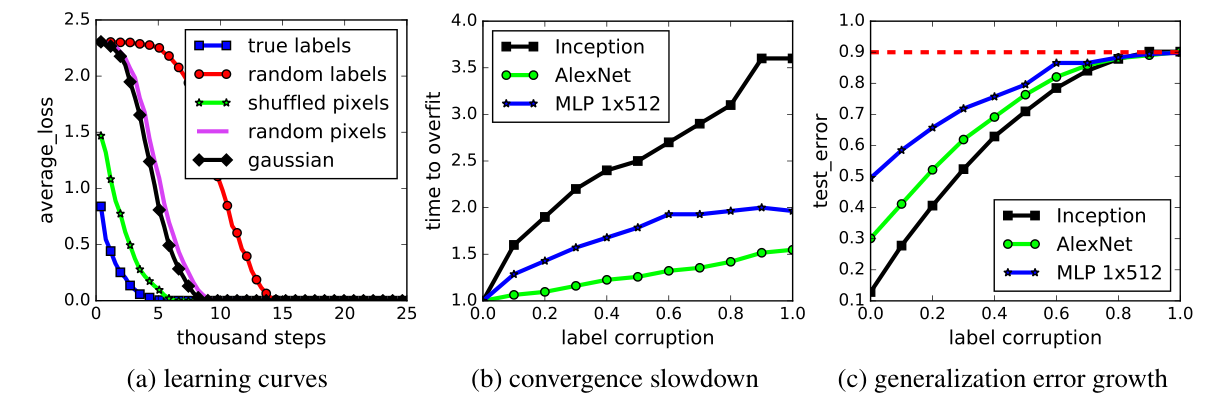

*Source: Figure 1 on page 4 of the PDF supplied with the assignment. The reproduced plots will be generated separately from saved metrics.*

## 1. Scope, mathematical question and approved deviations

**Question.** Can an overparameterized classifier fit arbitrary labels or unstructured images, and how do optimization time and clean-test accuracy vary with label corruption?

For the full CIFAR-10 dataset, write \(S_{\rm tr}=\{(x_i,y_i)\}_{i=1}^{50,000}\), with \(y_i\in\{0,\ldots,9\}\). For a corruption probability \(p\), draw **once** for each training example

\[
B_i\sim\operatorname{Bernoulli}(p),\quad U_i\sim\operatorname{Uniform}\{0,\ldots,9\},\quad
\tilde y_i=\begin{cases}U_i&B_i=1\\y_i&B_i=0.\end{cases}
\]

Replacement is allowed to draw the true label, so \(\Pr(\tilde y_i\ne y_i)=0.9p\). A single sampled target array is **fixed across every epoch**. Redrawing targets every epoch would change the experiment into an inconsistent-target stochastic problem rather than a memorization test. The model minimizes empirical cross entropy

\[
L_{\rm tr}(\theta)=-\frac1n\sum_{i=1}^n\log\left(\operatorname{softmax}(f_\theta(x_i))_{\tilde y_i}\right).
\]

The chosen convergence event is **end-of-epoch evaluation-mode accuracy of at least 99.0% over all 50,000 fixed training targets** (at least 49,500 correct). This is an **approved deviation** from the paper's discussion of zero training error. It measures **time to 99% fit** in optimizer steps, rather than an unspecified 'time to overfit':

\[
T_m(p)=\text{first recorded optimizer-step count with train accuracy }\geq 0.99,\qquad
R_m(p)=\frac{T_m(p)}{T_m(0)}.
\]

There is at most one epoch of measurement granularity; a run that never reaches 99% has **no** convergence time and must not contribute a false point to panel (b). Panel (c) plots the measured *clean-test classification error*, not necessarily exactly the generalization gap because training error can be nonzero:

\[e_{\rm gap}(p)=e_{\rm test}(p)-e_{\rm train,target}(p).\]

The 90% dashed test-error reference is a theoretical chance-level quantity for ten classes, **not** a copied experimental value.

### Approved experiment grid

| Panel | Model(s) | Training conditions | Measurement |
|:--|:--|:--|:--|
| (a) | Small Inception | True labels; fixed random labels; one shared spatial-pixel permutation; a **fixed independent** spatial-pixel permutation per image; per-image independent Gaussian noise matching the training-set **global** pixel mean/variance | Batch cross entropy vs optimizer updates |
| (b), (c) | Small Inception | \(p=0,0.2,0.4,0.6,0.8,1\) | 99%-fit slowdown; clean-test error |
| (b), (c) | MLP 1×512 | \(p=0,0.4,1\) | 99%-fit slowdown; clean-test error |

There are **12 unique runs**, not 5 + 6 + 3 = 14: the Inception true-label and fully random-label panel-(a) runs are **the same artifacts** as \(p=0\) and \(p=1\) for panels (b)/(c).

**Paper adaptations / omissions:** Original Figure 1(b,c) also uses AlexNet, which the user approved omitting. The MLP sweep is reduced to three points. Only one seed is used (no uncertainty intervals). The paper does not specify a CIFAR-10 minibatch size, a 'time to overfit' definition, a precise Gaussian matching granularity, or a channel-wise-versus-RGB-triplet pixel permutation convention. We use a documented batch size of 128, and permute **whole RGB pixel triplets spatially**; these are declared choices, not claims about undocumented author code. Performance settings: two independent single-GPU processes if Kaggle supplies T4×2 (one on Colab), GPU-resident CIFAR-10 tensors, and true FP32 with TF32/AMP disabled.

**Compute-limit warning:** No free-GPU protocol can *guarantee* that all 12 runs reach 99% within six hours. The optional protective wall-clock deadline allows an honest **incomplete** result rather than silently changing the definition of convergence. It does **not** turn a censored run into a valid slowdown measurement.

## 2. Exact model reconstruction, preprocessing and training rules

**Model architecture — small Inception, Figure 3 of the paper:** The arrow direction winds through the diagram; the block order matters. The implementation below uses two-path Inception modules (1×1 and 3×3 convolutions), parallel strided-conv/max-pool downsampling and global average pooling. **The resulting 1,649,402 trainable weights match Table 1 exactly.** The matching count is obtained with no convolutional bias and **batch normalization with fixed multiplicative scale 1 and a trainable additive offset**. This is an inference from the count, **not** an assertion that the authors' unreported batch-normalization configuration is known. The BN epsilon (0.001) and running-average momentum (0.001) are also explicit assumptions and potential sources of mismatch.

**MLP 1×512:** The 28×28×3 input flattens to 2,352 values and passes through 512 ReLU units and a 10-way linear output, with 1,209,866 trainable parameters (Table 1). The model does not have dropout or batch normalization.

**Preprocessing, Appendix A:** CIFAR-10 full **50,000/10,000** train/test split, original 32×32 images divided by 255, deterministic center-crop to 28×28, then per-image standardization \((x-\bar x)/\max(\sigma,1/\sqrt{2352})\). The same image preprocessing is used for both train and test. No random data augmentation, sample deletion, extra labeled data, pretrained weights, or test-guided tuning is used.

**Optimization, Appendix A:** SGD with momentum 0.9; initial learning rate 0.1 (Inception) or 0.01 (MLP), multiplied by 0.95 **after each epoch**. No weight decay or dropout. Baseline training hyperparameters are **unchanged as the labels or pixels are corrupted**. The full 50,000-image training accuracy is computed in **evaluation mode**, including fixed BN running estimates; only then can convergence be declared.

**Panels:** (a) logs genuine minibatch cross-entropy values versus number of optimizer updates. (b) divides measured update counts by the architecture's own measured \(p=0\) update count. (c) evaluates on CIFAR-10's original 10,000 clean test labels **after** the fitting criterion. Runs censored by the safety budgets appear only in the audit table, never as fictitious convergence points.

## 3. Theoretical context and what Figure 1 does *not* prove

The paper distinguishes *representational capacity*, *optimization*, and *generalization*. Interpolation of random labels shows capacity and an optimization route to memorization; poor clean-test performance under random labeling demonstrates that interpolation alone does not imply generalization. The paper's finite-sample ReLU construction (Theorem 1, §4 and Appendix C) defines \(f(x)=\sum_{j=1}^{n}w_j\operatorname{ReLU}(a^\top x-b_j)\); suitably chosen projections and thresholds give an invertible triangular interpolation matrix, allowing any scalar targets on \(n\) distinct inputs using \(2n+d\) parameters. This is an **existence theorem**, not an SGD convergence guarantee for this 512-unit MLP. The paper further critiques unrestricted worst-case capacity bounds, and considers implicit selection by gradient methods (§§2–5).

**Reporting requirements from the assignment:** State that the expected *changed-label fraction* is \(0.9p\) and chance-level clean-test error at \(p=1\) is 90%. Describe failure cases using measured loss, training accuracy, wall time, hardware, and parameter checks, **not guesses**. Save the Phase 3 code revision to version control **before** consulting any existing implementation in Phase 4. Report your own critical review before looking at public reviews; include the real chat share URL and model name in the final report. Make the GitHub repository public **on the submission day**, as the assignment requires.

## 4. Prepare a portable GPU notebook

**Kaggle:** Enable the `T4 ×2` GPU accelerator if offered. For the original CIFAR-10 dataset, use the permanent **Kaggle Datasets → New Dataset → Input → Add Input** workflow explained in §5 below, so that Kaggle never performs a slow network download at execution time. Internet can remain disabled once the archive has been attached.

**Colab:** Select a GPU runtime. It uses the normal torchvision download if the data is not already present. If training must survive session resets, persist your checkpoint/results directory outside the transient runtime (e.g., Google Drive).

**Required packages:** `torch`, `torchvision`, `numpy`, `pandas`, `matplotlib`, `Pillow`. No official or unofficial reproduction implementation is installed or consulted.

The notebook generates its own `zhang_fig1_core.py` source in the working directory via the next `%%writefile` cell; you need only upload the `.ipynb` and attach the dataset.

In [ ]:
import os, sys, json, time, subprocess, importlib
from pathlib import Path
import torch, numpy as np, pandas as pd, matplotlib.pyplot as plt
from IPython.display import display

WORK_DIR = Path.cwd()
DATA_ROOT = WORK_DIR / "cifar_data"
RESULTS_ROOT = WORK_DIR / "figure1_results"
RESULTS_ROOT.mkdir(parents=True, exist_ok=True)

# User-approved experimental scope; editable safeguard settings are disclosed.
TRAIN_ACCURACY = 0.99     # user-approved; >=49,500 / 50,000 correct
BATCH_SIZE = 128          # paper does NOT specify batch size; documented choice
MAX_EPOCHS = 200          # safety cap, NOT an assertion about convergence
EVAL_BATCH_SIZE = 512
CHECKPOINT_EVERY_EPOCHS = 1
LOSS_LOG_EVERY_UPDATES = 20
MAX_WORKER_GPUS = 2      # 2 if Kaggle T4x2 is available; 1 on Colab
MAX_WALL_HOURS = 5.75   # budget safeguard; never treats nonconvergence as success

assert TRAIN_ACCURACY == 0.99
print("Python:", sys.version.split()[0], "PyTorch:", torch.__version__)
print("CUDA available:", torch.cuda.is_available(), "CUDA devices:", torch.cuda.device_count())
if torch.cuda.is_available():
    for i in range(torch.cuda.device_count()):
        print(f"GPU {i}: {torch.cuda.get_device_name(i)}")
print("Artifacts:", RESULTS_ROOT)

In [ ]:
%%writefile zhang_fig1_core.py
"""Self-contained PyTorch reproduction engine for Zhang et al. (ICLR 2017), Fig. 1.

Original implementation from the description in the paper, not derived from
any third-party/official reproduction. Generated by the companion notebook.
"""
from __future__ import annotations

import argparse
import csv
import hashlib
import json
import math
import os
import random
import sys
import time
import traceback
from dataclasses import asdict, dataclass
from datetime import datetime, timezone
from pathlib import Path

import numpy as np
import torch
from torch import nn
import torch.nn.functional as F

ARCH_PARAM_COUNTS = {"inception": 1_649_402, "mlp": 1_209_866}
GLOBAL_SEED = 6362
# One RNG realization per condition, with shared initialization across conditions.
CORRUPTION_SEED = GLOBAL_SEED + 100
SHUFFLE_SEED = GLOBAL_SEED + 200
INDEPENDENT_PERM_SEED = GLOBAL_SEED + 300
GAUSSIAN_SEED = GLOBAL_SEED + 400


class OffsetOnlyBatchNorm2d(nn.Module):
    """Batch norm with learned beta and fixed gamma=1 (TF-style scale=False).

    This architectural inference is corroborated by the exact trainable
    parameter total reported for the paper's small Inception (1,649,402).
    eps=.001 and running-stat decay=.999 are documented assumptions, not
    settings specified directly in the paper.
    """

    def __init__(self, channels: int):
        super().__init__()
        self.bn = nn.BatchNorm2d(channels, eps=1e-3, momentum=0.001, affine=False)
        self.beta = nn.Parameter(torch.zeros(channels))

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        return self.bn(x) + self.beta[None, :, None, None]


class ConvModule(nn.Sequential):
    def __init__(self, cin: int, cout: int, kernel_size: int = 3, stride: int = 1):
        super().__init__(
            nn.Conv2d(cin, cout, kernel_size=kernel_size, stride=stride,
                      padding=kernel_size // 2, bias=False),
            OffsetOnlyBatchNorm2d(cout),
            nn.ReLU(inplace=True),
        )


class InceptionModule(nn.Module):
    def __init__(self, cin: int, ch1: int, ch3: int):
        super().__init__()
        self.one_by_one = ConvModule(cin, ch1, 1)
        self.three_by_three = ConvModule(cin, ch3, 3)

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        return torch.cat((self.one_by_one(x), self.three_by_three(x)), dim=1)


class DownsampleModule(nn.Module):
    def __init__(self, cin: int, ch3: int):
        super().__init__()
        self.conv = ConvModule(cin, ch3, kernel_size=3, stride=2)
        self.pool = nn.MaxPool2d(kernel_size=3, stride=2, padding=1)

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        return torch.cat((self.conv(x), self.pool(x)), dim=1)


class SmallInception(nn.Module):
    """Figure 3 of the supplied paper, following the diagram's snaking arrows."""
    def __init__(self):
        super().__init__()
        self.features = nn.Sequential(
            ConvModule(3, 96, 3),             # 28 x 28 x 96
            InceptionModule(96, 32, 32),      # 28 x 28 x 64
            InceptionModule(64, 32, 48),      # 28 x 28 x 80
            DownsampleModule(80, 80),         # 14 x 14 x 160
            InceptionModule(160, 112, 48),    # 14 x 14 x 160
            InceptionModule(160, 96, 64),     # 14 x 14 x 160
            InceptionModule(160, 80, 80),     # 14 x 14 x 160
            InceptionModule(160, 48, 96),     # 14 x 14 x 144
            DownsampleModule(144, 96),        # 7 x 7 x 240
            InceptionModule(240, 176, 160),   # 7 x 7 x 336
            InceptionModule(336, 176, 160),   # 7 x 7 x 336
            nn.AdaptiveAvgPool2d((1, 1)),
            nn.Flatten(),
        )
        self.classifier = nn.Linear(336, 10)

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        return self.classifier(self.features(x))


class MLP1x512(nn.Module):
    """2352 -> 512 -> 10, no dropout or batch normalization."""
    def __init__(self):
        super().__init__()
        self.layers = nn.Sequential(
            nn.Flatten(),
            nn.Linear(3 * 28 * 28, 512),
            nn.ReLU(inplace=True),
            nn.Linear(512, 10),
        )

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        return self.layers(x)


def build_model(architecture: str) -> nn.Module:
    if architecture == "inception":
        model = SmallInception()
    elif architecture == "mlp":
        model = MLP1x512()
    else:
        raise ValueError(f"Unknown architecture: {architecture!r}")
    num_params = sum(p.numel() for p in model.parameters() if p.requires_grad)
    assert num_params == ARCH_PARAM_COUNTS[architecture], (
        f"Architecture mismatch: {architecture} has {num_params:,} trainable parameters; "
        f"paper reports {ARCH_PARAM_COUNTS[architecture]:,}."
    )
    return model


def seed_training(seed: int = GLOBAL_SEED) -> None:
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)
    # True FP32, including preventing TF32 approximations on Ampere+ GPUs.
    torch.backends.cuda.matmul.allow_tf32 = False
    torch.backends.cudnn.allow_tf32 = False
    torch.set_float32_matmul_precision("highest")
    if torch.backends.cudnn.is_available():
        torch.backends.cudnn.benchmark = True  # fixed image and batch shapes
    # Do not force deterministic CuDNN kernels: can impose significant overhead.
    # Seeds are fixed, but bit-identical reproducibility across devices is not promised.


def gpu_generator(seed: int, device: torch.device) -> torch.Generator:
    return torch.Generator(device=device.type).manual_seed(seed)


def make_fixed_labels(y: torch.Tensor, p: float, seed: int = CORRUPTION_SEED):
    """Bernoulli(p) replacement with Uniform(10), sampled ONCE per run.

    The same uniforms across different p values yield a nested corruption grid,
    reducing nuisance variation in a single-seed comparison.
    """
    assert 0 <= p <= 1
    device = y.device
    g = gpu_generator(seed, device)
    threshold_draws = torch.rand(y.shape, generator=g, device=device)
    replacement = torch.randint(0, 10, y.shape, generator=g, device=device)
    selected = threshold_draws < p
    target = torch.where(selected, replacement, y).long()
    return target, {
        "nominal_probability": float(p),
        "selected_fraction": float(selected.float().mean().item()),
        "changed_fraction": float((target != y).float().mean().item()),
        "expected_changed_fraction": 0.9 * float(p),
    }


def center_crop_28(x: torch.Tensor) -> torch.Tensor:
    """(N, 32, 32, 3) uint8 NHWC -> (N, 3, 28, 28) float32 / 255."""
    assert x.ndim == 4 and x.shape[1:] == (32, 32, 3)
    return x[:, 2:30, 2:30, :].permute(0, 3, 1, 2).contiguous().float().div_(255.)


def per_image_standardization(x: torch.Tensor) -> torch.Tensor:
    """TensorFlow per_image_whitening/standardization convention.

    (x - mean)/max(population_std,1/sqrt(28*28*3)), computed per image over
    ALL spatial and color values. Applies AFTER the input corruption.
    """
    assert x.ndim == 4 and x.shape[1:] == (3, 28, 28)
    means = x.mean(dim=(1, 2, 3), keepdim=True)
    stds = torch.sqrt(torch.mean((x - means) ** 2, dim=(1, 2, 3), keepdim=True))
    stds = torch.clamp_min(stds, 1.0 / math.sqrt(3 * 28 * 28))
    return ((x - means) / stds).contiguous()


def permute_rgb_pixels(x: torch.Tensor, perm: torch.Tensor) -> torch.Tensor:
    """Permute 28x28 spatial RGB triplets, not individual color channels.

    Paper says 'pixels' without specifying whether RGB channels are bound;
    we explicitly choose the physically meaningful RGB-triplet convention.
    """
    n = x.shape[0]
    spatial = x.permute(0, 2, 3, 1).reshape(n, 784, 3)
    if perm.ndim == 1:
        out = spatial[:, perm, :]
    else:
        assert perm.shape == (n, 784)
        out = spatial.gather(1, perm[..., None].expand(-1, -1, 3))
    return out.reshape(n, 28, 28, 3).permute(0, 3, 1, 2).contiguous()


def distort_input(x: torch.Tensor, kind: str, *, split: str,
                  gaussian_mean: float | None = None,
                  gaussian_std: float | None = None) -> torch.Tensor:
    """Generate a fixed image corruption once (never per epoch)."""
    if kind == "true":
        return x
    device = x.device
    if kind == "shuffled_pixels":
        g = gpu_generator(SHUFFLE_SEED, device)
        perm = torch.randperm(784, generator=g, device=device)
        return permute_rgb_pixels(x, perm)
    if kind == "random_pixels":
        g = gpu_generator(INDEPENDENT_PERM_SEED + (0 if split == "train" else 1), device)
        # Independent random permutation for EACH IMAGE, fixed across epochs.
        # Chunks bound the peak temporary memory footprint of argsort.
        chunks = []
        for batch in x.split(2048):
            perm = torch.rand(batch.shape[0], 784, generator=g, device=device).argsort(dim=1)
            chunks.append(permute_rgb_pixels(batch, perm))
        return torch.cat(chunks, dim=0)
    if kind == "gaussian":
        assert gaussian_mean is not None and gaussian_std is not None
        g = gpu_generator(GAUSSIAN_SEED + (0 if split == "train" else 1), device)
        # Dataset-matched SINGLE global mean/variance, NOT per-image-matched noise.
        return (torch.randn(x.shape, dtype=torch.float32, device=device, generator=g)
                * float(gaussian_std) + float(gaussian_mean))
    raise ValueError(f"Unknown input modification: {kind}")


def load_cifar_arrays(root: str, download: bool):
    from torchvision.datasets import CIFAR10
    train = CIFAR10(root=root, train=True, download=download)
    test = CIFAR10(root=root, train=False, download=download)
    return (train.data, np.asarray(train.targets, dtype=np.int64),
            test.data, np.asarray(test.targets, dtype=np.int64))


def prepare_cifar(root: str) -> None:
    """Run in notebook parent once, before starting parallel workers."""
    a, b, c, d = load_cifar_arrays(root, download=True)
    assert a.shape == (50_000, 32, 32, 3) and c.shape == (10_000, 32, 32, 3)
    assert b.shape == (50_000,) and d.shape == (10_000,)
    print(f"Verified CIFAR-10: {len(a):,} train / {len(c):,} test; cached in {root}")


@dataclass(frozen=True)
class Experiment:
    name: str
    architecture: str
    corruption_probability: float
    input_kind: str = "true"


def experiment_grid():
    # User-approved grid: 6 levels Inception, 3 levels MLP; 5 panel-(a) conditions.
    inc_levels = (0., 0.2, 0.4, 0.6, 0.8, 1.)
    mlp_levels = (0., 0.4, 1.)
    result = [Experiment(f"inception_labels_p{round(10*p):02d}", "inception", p)
              for p in inc_levels]
    result.extend(Experiment(f"inception_{kind}", "inception", 0., kind)
                  for kind in ("shuffled_pixels", "random_pixels", "gaussian"))
    result.extend(Experiment(f"mlp_labels_p{round(10*p):02d}", "mlp", p)
                  for p in mlp_levels)
    assert len(result) == 12 and len({exp.name for exp in result}) == 12
    return result


def load_experiment_data(exp: Experiment, root: str, device: torch.device):
    tr_x_np, tr_y_np, te_x_np, te_y_np = load_cifar_arrays(root, download=False)
    tr_x = center_crop_28(torch.from_numpy(tr_x_np).to(device))
    te_x = center_crop_28(torch.from_numpy(te_x_np).to(device))
    true_train_y = torch.from_numpy(tr_y_np).to(device)
    true_test_y = torch.from_numpy(te_y_np).to(device)
    # Gaussian statistics computed from UNCORRUPTED TRAINING PIXELS, not test pixels.
    dataset_mean = tr_x.mean().item() if exp.input_kind == "gaussian" else None
    dataset_std = tr_x.std(unbiased=False).item() if exp.input_kind == "gaussian" else None
    tr_x = distort_input(tr_x, exp.input_kind, split="train",
                         gaussian_mean=dataset_mean, gaussian_std=dataset_std)
    # The paper defines the same global pixel permutation on train+test, but
    # test images are never used to fit parameters. Evaluate test ONLY for label
    # experiments, keeping panel (a)'s extra runs fast.
    if exp.input_kind == "shuffled_pixels":
        te_x = distort_input(te_x, "shuffled_pixels", split="test")
    elif exp.input_kind == "random_pixels":
        te_x = distort_input(te_x, "random_pixels", split="test")
    elif exp.input_kind == "gaussian":
        te_x = distort_input(te_x, "gaussian", split="test",
                             gaussian_mean=dataset_mean, gaussian_std=dataset_std)
    tr_x = per_image_standardization(tr_x)
    te_x = per_image_standardization(te_x)
    labels, stat = make_fixed_labels(true_train_y, exp.corruption_probability)
    return tr_x, labels, te_x, true_test_y, stat


@torch.inference_mode()
def full_accuracy(model: nn.Module, x: torch.Tensor, y: torch.Tensor,
                  eval_batch_size: int = 512):
    was_training = model.training
    model.eval()
    n_correct = 0
    for j in range(0, len(y), eval_batch_size):
        xb = x[j:j + eval_batch_size]
        pred = model(xb).argmax(dim=1)
        n_correct += int((pred == y[j:j+eval_batch_size]).sum().item())
    if was_training:
        model.train()
    return n_correct / len(y), n_correct


def atomic_save_torch(obj, target: Path):
    temp = target.with_name(target.name + ".writing")
    torch.save(obj, temp)
    temp.replace(target)


def atomic_save_json(obj, target: Path):
    temp = target.with_name(target.name + ".writing")
    temp.write_text(json.dumps(obj, indent=2, sort_keys=True) + "\n", encoding="utf-8")
    temp.replace(target)


def truncate_csv_after_checkpoint(path: Path, max_updates: int, *, epoch_limit: int | None = None):
    """Drop log rows created after the most recent complete checkpoint.

    A wall-time guard can interrupt training in the middle of an epoch. In
    that case the prior completed-epoch checkpoint is authoritative and all
    subsequent log entries must be discarded before resuming.
    """
    if not path.exists():
        return
    with path.open(newline="", encoding="utf-8") as stream:
        reader = csv.DictReader(stream)
        fields = reader.fieldnames
        rows = [r for r in reader if int(r["updates"]) <= max_updates
                and (epoch_limit is None or int(r["epoch"]) <= epoch_limit)]
    tmp = path.with_suffix(path.suffix + ".writing")
    with tmp.open("w", newline="", encoding="utf-8") as stream:
        writer = csv.DictWriter(stream, fieldnames=fields)
        writer.writeheader()
        writer.writerows(rows)
    tmp.replace(path)


def rows_append_csv(path: Path, row: dict, fieldnames: tuple):
    exists = path.exists()
    with path.open("a", newline="", encoding="utf-8") as stream:
        writer = csv.DictWriter(stream, fieldnames=fieldnames)
        if not exists:
            writer.writeheader()
        writer.writerow(row)


EPOCH_FIELDS = ("epoch", "updates", "train_accuracy", "train_correct",
                "train_loss_online", "learning_rate", "epoch_seconds",
                "elapsed_seconds")
LOSS_FIELDS = ("updates", "epoch", "batch_cross_entropy")


def exp_output(root: str | Path, exp: Experiment) -> Path:
    return Path(root) / exp.name


def run_experiment(exp: Experiment, *, data_root: str, results_root: str,
                   batch_size: int, max_epochs: int, threshold: float,
                   eval_batch_size: int, log_every: int, checkpoint_every: int,
                   deadline_unix: float | None = None) -> dict:
    """Train ONE independent run in ONE worker (one CUDA_VISIBLE_DEVICES GPU)."""
    assert torch.cuda.is_available(), "Full experiment requires GPU; CPU runs are intentionally blocked."
    assert 0.0 < threshold <= 1.0
    assert batch_size > 0 and max_epochs > 0
    torch.set_num_threads(2)
    seed_training()
    device = torch.device("cuda:0")  # mapped by subprocess CUDA_VISIBLE_DEVICES
    out = exp_output(results_root, exp)
    out.mkdir(parents=True, exist_ok=True)
    status_path, ckpt_path = out / "status.json", out / "checkpoint.pt"
    source_hash = hashlib.sha256(Path(__file__).read_bytes()).hexdigest()
    metadata_path = out / "metadata.json"
    if metadata_path.exists():
        existing_metadata = json.loads(metadata_path.read_text())
        if (existing_metadata.get("batch_size") != batch_size
                or existing_metadata.get("threshold") != threshold
                or existing_metadata.get("source_sha256") != source_hash):
            raise ValueError("Settings/code differ from this run's existing artifacts. "
                             "Choose a NEW RESULTS_ROOT; never mix incompatible runs.")
    if status_path.exists():
        prev_status = json.loads(status_path.read_text())
        if prev_status.get("status") == "converged":
            print(f"Already converged: {exp.name}; skipping", flush=True)
            return prev_status
        if (prev_status.get("status") == "max_epochs_reached"
                and int(prev_status.get("latest_complete_epoch") or 0) >= max_epochs):
            print(f"Already reached max_epochs={max_epochs}: {exp.name}; "
                  "increase MAX_EPOCHS explicitly to continue", flush=True)
            return prev_status

    tr_x, tr_y, te_x, te_y, corruption_info = load_experiment_data(exp, data_root, device)
    model = build_model(exp.architecture).to(device)
    lr = 0.1 if exp.architecture == "inception" else 0.01
    optimizer = torch.optim.SGD(model.parameters(), lr=lr, momentum=0.9, weight_decay=0)
    scheduler = torch.optim.lr_scheduler.ExponentialLR(optimizer, gamma=0.95)
    shuffle_generator = gpu_generator(GLOBAL_SEED + 500, device)
    start_epoch, updates, previous_elapsed = 1, 0, 0.0
    if ckpt_path.exists():
        ckpt = torch.load(ckpt_path, map_location="cpu", weights_only=False)
        if (ckpt["exp"] != asdict(exp) or ckpt["batch_size"] != batch_size
                or ckpt["threshold"] != threshold):
            raise ValueError("Checkpoint was created with different settings; do not silently resume.")
        model.load_state_dict(ckpt["model"])
        optimizer.load_state_dict(ckpt["optimizer"])
        scheduler.load_state_dict(ckpt["scheduler"])
        # The optimizer states loaded from CPU checkpoint must be returned to the GPU.
        for st in optimizer.state.values():
            for key, value in st.items():
                if isinstance(value, torch.Tensor):
                    st[key] = value.to(device)
        shuffle_generator.set_state(ckpt["shuffle_state"])
        torch.set_rng_state(ckpt["cpu_rng_state"])
        torch.cuda.set_rng_state(ckpt["cuda_rng_state"], device=device)
        start_epoch = int(ckpt["next_epoch"])
        updates = int(ckpt["updates"])
        previous_elapsed = float(ckpt.get("elapsed_seconds", 0.0))
        truncate_csv_after_checkpoint(out / "loss_steps.csv", updates)
        truncate_csv_after_checkpoint(out / "epochs.csv", updates, epoch_limit=start_epoch - 1)
        print(f"Resuming {exp.name} from epoch {start_epoch}, update {updates}", flush=True)
    else:
        # An external notebook interruption may have left a partial *first*
        # epoch with CSV samples but no completed-epoch checkpoint.
        # The seeded restart is authoritative: remove those stale samples.
        for filename in ("loss_steps.csv", "epochs.csv"):
            stale = out / filename
            if stale.exists():
                print(f"No checkpoint: dropping incomplete logs {stale}", flush=True)
                stale.unlink()

    metadata = {
        "exp": asdict(exp), "random_seed": GLOBAL_SEED, "batch_size": batch_size,
        "threshold": threshold, "max_epochs": max_epochs,
        "lr_initial": lr, "lr_epoch_multiplier": 0.95,
        "optimizer": "SGD momentum=0.9; weight_decay=0; Nesterov=false",
        "preprocessing": "28x28 center crop, /255, per-image standardization",
        "numerical_precision": "FP32; TF32 disabled; AMP disabled",
        "corruption": corruption_info,
        "train_count": len(tr_y), "test_count": len(te_y),
        "parameters": sum(p.numel() for p in model.parameters() if p.requires_grad),
        "hardware": torch.cuda.get_device_name(0),
        "torch_version": torch.__version__,
        "source_sha256": source_hash,
        "utc_start": datetime.now(timezone.utc).isoformat(),
    }
    atomic_save_json(metadata, out / "metadata.json")

    clock_start = time.monotonic()
    last_epoch, latest_acc, latest_correct = start_epoch - 1, None, None

    def checkpoint(next_epoch: int):
        atomic_save_torch({
            "exp": asdict(exp), "batch_size": batch_size, "threshold": threshold,
            "model": model.state_dict(), "optimizer": optimizer.state_dict(),
            "scheduler": scheduler.state_dict(), "next_epoch": next_epoch,
            "updates": updates,
            "shuffle_state": shuffle_generator.get_state(),
            "cpu_rng_state": torch.get_rng_state(),
            "cuda_rng_state": torch.cuda.get_rng_state(),
            "elapsed_seconds": previous_elapsed + time.monotonic() - clock_start,
        }, ckpt_path)

    state = "max_epochs_reached"
    for epoch in range(start_epoch, max_epochs + 1):
        if deadline_unix is not None and time.time() >= deadline_unix - 90:
            state = "time_budget_reached"
            break
        epoch_start = time.monotonic()
        model.train()
        order = torch.randperm(len(tr_y), generator=shuffle_generator, device=device)
        total_loss = torch.zeros((), device=device)
        batch_count = 0
        epoch_fully_completed = True
        for lo in range(0, len(tr_y), batch_size):
            if deadline_unix is not None and time.time() >= deadline_unix - 90:
                epoch_fully_completed = False
                state = "time_budget_reached"
                break
            indices = order[lo:lo + batch_size]
            xb, yb = tr_x[indices], tr_y[indices]
            optimizer.zero_grad(set_to_none=True)
            loss = F.cross_entropy(model(xb), yb)
            loss.backward()
            optimizer.step()
            updates += 1
            bs = yb.shape[0]
            total_loss += loss.detach() * bs
            batch_count += bs
            if updates == 1 or updates % log_every == 0:
                rows_append_csv(out / "loss_steps.csv",
                                {"updates": updates, "epoch": epoch,
                                 "batch_cross_entropy": float(loss.detach().item())}, LOSS_FIELDS)
        if not epoch_fully_completed:
            # An incomplete epoch cannot be represented as completed. Since
            # the shuffle order is only stored per epoch, discard this partial
            # epoch's progress and resume from the prior checkpoint next time.
            # The checkpoint does NOT incorporate partially completed weights.
            # Re-load immediately to avoid misrepresenting completed updates.
            if ckpt_path.exists():
                print(f"Budget reached inside epoch {epoch}; prior checkpoint remains valid", flush=True)
            else:
                print("Budget reached during first epoch; re-run from initialization", flush=True)
            break
        torch.cuda.synchronize()
        acc, correct = full_accuracy(model, tr_x, tr_y, eval_batch_size)
        torch.cuda.synchronize()
        epoch_seconds = time.monotonic() - epoch_start
        elapsed = previous_elapsed + time.monotonic() - clock_start
        online_loss = float(total_loss.item() / batch_count)
        rows_append_csv(out / "epochs.csv", {
            "epoch": epoch, "updates": updates, "train_accuracy": acc,
            "train_correct": correct, "train_loss_online": online_loss,
            "learning_rate": optimizer.param_groups[0]["lr"],
            "epoch_seconds": round(epoch_seconds, 3),
            "elapsed_seconds": round(elapsed, 3)
        }, EPOCH_FIELDS)
        latest_acc, latest_correct, last_epoch = acc, correct, epoch
        print(f"{exp.name} epoch={epoch:04d} updates={updates:07d} "
              f"train_acc={acc:.5f} mean_loss={online_loss:.5f} "
              f"epoch_s={epoch_seconds:.1f}", flush=True)
        scheduler.step()  # 0.95 decay PER completed epoch, as in paper
        if acc >= threshold:
            state = "converged"
            checkpoint(epoch + 1)
            break
        if epoch % checkpoint_every == 0:
            checkpoint(epoch + 1)

    if state != "converged" and last_epoch >= start_epoch:
        # A partially completed epoch is never checkpointed as completed.
        if epoch_fully_completed:
            checkpoint(last_epoch + 1)
    test_acc = None
    if state == "converged" or (last_epoch >= start_epoch and epoch_fully_completed):
        # End-of-budget metrics must come from a completed epoch only.
        if exp.input_kind == "true":
            test_acc, _ = full_accuracy(model, te_x, te_y, eval_batch_size)
    final = {
        "exp": asdict(exp), "status": state, "converged": state == "converged",
        "convergence_updates": updates if state == "converged" else None,
        "convergence_epochs": last_epoch if state == "converged" else None,
        "latest_complete_epoch": last_epoch,
        "latest_train_accuracy": latest_acc,
        "latest_train_correct": latest_correct,
        "test_accuracy": test_acc,
        "test_error": (1.0 - test_acc) if test_acc is not None else None,
        "target_train_error": 1.0 - latest_acc if latest_acc is not None else None,
        "elapsed_seconds_total": previous_elapsed + time.monotonic() - clock_start,
        "updates_at_finish": updates,
        "partial_epoch_not_checkpointed": (state == "time_budget_reached" and
                                            last_epoch >= start_epoch and not epoch_fully_completed),
        "corruption": corruption_info,
        "evaluated_in_eval_mode": True,
        "utc_finish": datetime.now(timezone.utc).isoformat(),
    }
    atomic_save_json(final, status_path)
    print(f"FINISHED {exp.name}: status={state} ", final, flush=True)
    return final


def smoke_tests(verbose=True):
    """CPU-only functional checks; no CIFAR download and no fake plotted values."""
    seed_training()
    m_inc = build_model("inception")
    m_mlp = build_model("mlp")
    assert sum(p.numel() for p in m_inc.parameters() if p.requires_grad) == 1_649_402
    assert sum(p.numel() for p in m_mlp.parameters() if p.requires_grad) == 1_209_866
    x = torch.randn(2, 3, 28, 28)
    with torch.no_grad():
        assert m_inc(x).shape == (2, 10)
        assert m_mlp(x).shape == (2, 10)
    m_inc.eval()
    assert m_inc(x).isfinite().all()
    m_inc.train()
    assert all(p.grad is None for p in m_inc.parameters())
    loss = F.cross_entropy(m_inc(x), torch.tensor([0, 1]))
    loss.backward()
    assert m_inc.classifier.weight.grad is not None
    assert torch.isfinite(m_inc.classifier.weight.grad).all()
    yy = torch.arange(5000) % 10
    for p in [0., .2, .4, .6, .8, 1.]:
        z1, s1 = make_fixed_labels(yy, p)
        z2, s2 = make_fixed_labels(yy, p)
        assert torch.equal(z1, z2), "Labels must be fixed across epochs"
        assert abs(s1["changed_fraction"] - .9 * p) < .02
    labels_0, _ = make_fixed_labels(yy, 0.)
    labels_1, _ = make_fixed_labels(yy, 1.)
    assert torch.equal(labels_0, yy)
    assert set(labels_1.tolist()) == set(range(10))
    image = torch.randn(4, 3, 28, 28)
    sh1 = distort_input(image, "shuffled_pixels", split="train")
    sh2 = distort_input(image, "shuffled_pixels", split="test")
    assert torch.equal(sh1, sh2), "Shared permutation must hold for train and test"
    rnd1 = distort_input(image, "random_pixels", split="train")
    rnd2 = distort_input(image, "random_pixels", split="train")
    assert torch.equal(rnd1, rnd2), "Per-image permutations must remain fixed"
    assert not torch.equal(rnd1[0], rnd1[1])
    for i in range(4):
        # Each permuted channel contains exactly the input channel elements.
        for c in range(3):
            assert torch.equal(torch.sort(rnd1[i,c].flatten())[0],
                               torch.sort(image[i,c].flatten())[0])
    xx = per_image_standardization(image)
    assert (xx.mean((1,2,3)).abs() < 1e-5).all()
    assert ((xx.std((1,2,3), unbiased=False) - 1).abs() < 1e-4).all()
    assert len(experiment_grid()) == 12
    if verbose:
        print("PASS: architecture parameter counts, forward passes, seeded fixed labels, ")
        print("      0.9p corruption, shared/per-image permutations, whitening, 12-run grid")
    return True


def cli():
    parser = argparse.ArgumentParser(description=__doc__)
    parser.add_argument("--self-test", action="store_true")
    parser.add_argument("--experiment", type=str)
    parser.add_argument("--data-root", default="./cifar_data")
    parser.add_argument("--results-root", default="./figure1_results")
    parser.add_argument("--batch-size", type=int, default=128)
    parser.add_argument("--max-epochs", type=int, default=120)
    parser.add_argument("--accuracy", type=float, default=.99)
    parser.add_argument("--eval-batch-size", type=int, default=512)
    parser.add_argument("--loss-log-every", type=int, default=20)
    parser.add_argument("--checkpoint-every", type=int, default=1)
    parser.add_argument("--deadline-unix", type=float, default=None)
    args = parser.parse_args()
    if args.self_test:
        smoke_tests()
        return
    experiments = {e.name: e for e in experiment_grid()}
    if args.experiment not in experiments:
        parser.error(f"--experiment required; choose from: {list(experiments)}")
    try:
        run_experiment(experiments[args.experiment], data_root=args.data_root,
                       results_root=args.results_root, batch_size=args.batch_size,
                       max_epochs=args.max_epochs, threshold=args.accuracy,
                       eval_batch_size=args.eval_batch_size,
                       log_every=args.loss_log_every, checkpoint_every=args.checkpoint_every,
                       deadline_unix=args.deadline_unix)
    except Exception:
        err_dir = Path(args.results_root) / args.experiment
        err_dir.mkdir(parents=True, exist_ok=True)
        (err_dir / "failure.txt").write_text(traceback.format_exc(), encoding="utf-8")
        traceback.print_exc()
        sys.exit(1)


if __name__ == "__main__":
    cli()


In [ ]:
import importlib, zhang_fig1_core as repro
importlib.reload(repro)
assert repro.smoke_tests()
for e in repro.experiment_grid():
    print(f"{e.name:32} {e.architecture:9}  p={e.corruption_probability:.1f}  input={e.input_kind}")
print("Smoke tests passed. No training result has been generated yet.")

## 5. Prepare the original CIFAR-10 dataset without a repeated download

**Kaggle (preferred):** Download the original [CIFAR-10 Python archive](https://www.cs.toronto.edu/~kriz/cifar-10-python.tar.gz) **once**, and create a **Private Kaggle Dataset** containing the untouched `cifar-10-python.tar.gz`. In the notebook's **Input → Add Input**, attach that dataset. (An extracted `cifar-10-batches-py/` directory or ZIP of that original folder also works.)

The following cell locates the attachment beneath `/kaggle/input`, stages the **seven original Python-format files** into the writable `DATA_ROOT`, and verifies them through `torchvision.datasets.CIFAR10(download=False)`. **It never downloads CIFAR-10 over the network when running on Kaggle**; missing or malformed input produces a helpful error. Extraction/copying from the Kaggle mount is local and much faster than network downloading.

**Colab/local:** If `/kaggle/input` is absent, the cell uses the regular torchvision download/cache behavior. The original 50,000 training and 10,000 test examples are always preserved. No alternate dataset or third-party model implementation is used.

In [ ]:
# Kaggle: use an ATTACHED private/public CIFAR-10 dataset (no network download).
# Colab/local: keep torchvision's normal downloader as an alternative.
import shutil
import tarfile
import zipfile
from pathlib import Path

_CIFAR_FILES = tuple(f"data_batch_{i}" for i in range(1, 6)) + (
    "test_batch", "batches.meta")


def _is_original_python_cifar(folder: Path) -> bool:
    return all((folder / file).is_file() for file in _CIFAR_FILES)


def stage_attached_cifar(data_root: Path, kaggle_input: Path = Path("/kaggle/input")) -> str:
    """Stage ORIGINAL CIFAR-10 Python files from Kaggle's read-only input.

    Accepts the seven files already extracted (inside any dataset directory),
    cifar-10-python.tar.gz, or a ZIP containing cifar-10-batches-py/.
    The source stays unchanged. torchvision verifies each file's MD5 below.
    """
    target = data_root / "cifar-10-batches-py"
    if _is_original_python_cifar(target):
        return f"Already staged: {target}"

    if not kaggle_input.is_dir():
        raise FileNotFoundError(f"Kaggle dataset mount does not exist: {kaggle_input}")

    # Kaggle may expand ZIP uploads automatically, so prefer these directories.
    for first_batch in sorted(kaggle_input.rglob("data_batch_1")):
        folder = first_batch.parent
        if not _is_original_python_cifar(folder):
            continue
        target.mkdir(parents=True, exist_ok=True)
        for file in _CIFAR_FILES:
            shutil.copy2(folder / file, target / file)
        return f"Copied original CIFAR-10 Python files from {folder}"

    # If the original tar.gz archive is mounted unchanged, extract ONLY the
    # expected seven files. No tar path traversal or network access is possible.
    for archive in sorted(kaggle_input.rglob("*.tar.gz")):
        if "cifar" not in archive.name.lower():
            continue
        with tarfile.open(archive, mode="r:gz") as tf:
            names = [f"cifar-10-batches-py/{file}" for file in _CIFAR_FILES]
            try:
                members = [tf.getmember(name) for name in names]
            except KeyError:
                continue
            if not all(m.isfile() for m in members):
                continue
            target.mkdir(parents=True, exist_ok=True)
            for file, member in zip(_CIFAR_FILES, members):
                with tf.extractfile(member) as source, (target / file).open("wb") as dest:
                    shutil.copyfileobj(source, dest)
            return f"Extracted seven original Python files from {archive}"

    # A ZIP may be mounted without automatic extraction depending on how it
    # was uploaded. Read expected names explicitly, rather than extracting all.
    for archive in sorted(kaggle_input.rglob("*.zip")):
        with zipfile.ZipFile(archive) as zf:
            names = [f"cifar-10-batches-py/{file}" for file in _CIFAR_FILES]
            if not all(name in zf.namelist() for name in names):
                continue
            target.mkdir(parents=True, exist_ok=True)
            for file, member in zip(_CIFAR_FILES, names):
                with zf.open(member) as source, (target / file).open("wb") as dest:
                    shutil.copyfileobj(source, dest)
            return f"Extracted seven original Python files from {archive}"

    raise FileNotFoundError(
        "Could not find original CIFAR-10 Python-format files in /kaggle/input. "
        "Upload cifar-10-python.tar.gz as a Kaggle dataset, attach it using "
        "Add Input, and rerun this cell. No download was attempted."
    )


if Path("/kaggle/input").is_dir():
    print(stage_attached_cifar(DATA_ROOT))
    # CRITICAL: download=False; never wait for an internet download on Kaggle.
    train_x, train_y, test_x, test_y = repro.load_cifar_arrays(
        str(DATA_ROOT), download=False)
    assert train_x.shape == (50_000, 32, 32, 3)
    assert test_x.shape == (10_000, 32, 32, 3)
    print("Verified 50,000 CIFAR-10 training and 10,000 test images; network download disabled.")
    del train_x, train_y, test_x, test_y
else:
    # Google Colab/local Jupyter: standard initial download and file caching.
    repro.prepare_cifar(str(DATA_ROOT))


## 6. Parallel, resumable training — execute on the GPU

Two workers are launched **as separate Python processes**, each bound to **one physical GPU** through `CUDA_VISIBLE_DEVICES`. No data-parallel splitting of a single experiment occurs. The primary GPU prioritizes Inception; the second prioritizes MLP and then picks up remaining Inception runs. On a single GPU the scheduler completes both architecture queues serially. Each run writes its own `metadata.json`, `loss_steps.csv`, `epochs.csv`, `status.json`, `checkpoint.pt` and `worker.log` under `figure1_results/<run_id>/`.

**Runtime budget** starts when you execute the training cell (not during dataset download). Workers check the deadline between mini-batches and stop gracefully before it, using complete-epoch checkpoints. If a run is interrupted, restarting the training cell resumes its last completed-epoch checkpoint and trims logs beyond the checkpoint to prevent double-counting. If strict 99% was not reached, status is `time_budget_reached` or `max_epochs_reached`, not `converged`. A 5h45m safeguard leaves time for status files and plotting before six hours, but neither it nor parallel execution can guarantee all runs converge.

*If you want no automatic time limit, change `MAX_WALL_HOURS = None` in the configuration; that would remove the six-hour safety guarantee.*

In [ ]:
# Optional: review the full job list and settings BEFORE launching expensive training.
all_experiments = repro.experiment_grid()
print(f"{len(all_experiments)} unique training runs | FP32 | batch={BATCH_SIZE} | target={TRAIN_ACCURACY:.0%}")
print(f"Guard: max {MAX_EPOCHS} epochs/run and {MAX_WALL_HOURS} hours total (if set)")
for e in all_experiments:
    print(" ", e.name)

In [ ]:
from collections import deque

def run_all_experiments():
    import sys, subprocess, time, os, json
    from collections import deque
    available = torch.cuda.device_count()
    if available < 1:
        raise RuntimeError("A CUDA GPU is required. Enable a GPU in Kaggle/Colab settings first.")
    gpu_count = min(available, MAX_WORKER_GPUS)
    # These named jobs remain separate, each with original CIFAR-10 images.
    inc_preferred = ["inception_labels_p00", "inception_labels_p10",
                     "inception_shuffled_pixels", "inception_random_pixels", "inception_gaussian",
                     "inception_labels_p02", "inception_labels_p04",
                     "inception_labels_p06", "inception_labels_p08"]
    mlp_preferred = ["mlp_labels_p00", "mlp_labels_p10", "mlp_labels_p04"]
    by_name = {e.name: e for e in repro.experiment_grid()}
    assert set(inc_preferred + mlp_preferred) == set(by_name)
    def done(exp_name):
        status_file = RESULTS_ROOT / exp_name / "status.json"
        if not status_file.exists():
            return False
        status = json.loads(status_file.read_text())
        if status.get("converged", False):
            metadata_file = RESULTS_ROOT / exp_name / "metadata.json"
            if not metadata_file.exists():
                raise ValueError(f"No metadata for converged run {exp_name}.")
            metadata = json.loads(metadata_file.read_text())
            import hashlib
            running_source_hash = hashlib.sha256((WORK_DIR / "zhang_fig1_core.py").read_bytes()).hexdigest()
            if (metadata.get("batch_size") != BATCH_SIZE
                    or metadata.get("threshold") != TRAIN_ACCURACY
                    or metadata.get("source_sha256") != running_source_hash):
                raise ValueError(f"Incompatible prior result {exp_name}. "
                                 "Use a fresh RESULTS_ROOT for changed settings.")
            return True
        return False
    pending_inc = deque(n for n in inc_preferred if not done(n))
    pending_mlp = deque(n for n in mlp_preferred if not done(n))
    print(f"Already converged: {12 - len(pending_inc) - len(pending_mlp)}/12")
    if not pending_inc and not pending_mlp:
        print("All experiments already converged. Nothing to train.")
        return
    start = time.monotonic()
    deadline = (time.time() + MAX_WALL_HOURS * 3600
                if MAX_WALL_HOURS is not None else None)
    jobs = {}  # gpu_id -> (Popen, output_stream, name)
    last_report = 0.0
    def pop_next(gpu_id):
        primary, secondary = ((pending_mlp, pending_inc)
                              if gpu_count > 1 and gpu_id == 1
                              else (pending_inc, pending_mlp))
        for q in (primary, secondary):
            while q:
                name = q.popleft()
                if not done(name):
                    return name
        return None
    try:
        while pending_inc or pending_mlp or jobs:
            # Collect completed processes; propagate failures via log/status.
            for gpu_id, (proc, logfile, name) in list(jobs.items()):
                code_return = proc.poll()
                if code_return is not None:
                    logfile.close()
                    del jobs[gpu_id]
                    status_file = RESULTS_ROOT / name / "status.json"
                    status_name = (json.loads(status_file.read_text()).get("status")
                                   if status_file.exists() else "NO STATUS")
                    print(f"GPU {gpu_id} finished {name}: process={code_return}, result={status_name}")
                    if code_return != 0:
                        print("  WARNING: inspect", RESULTS_ROOT / name / "worker.log")
            time_left = (deadline - time.time()) if deadline is not None else float('inf')
            if time_left <= 300 and (pending_inc or pending_mlp):
                print("Guard reached: no NEW runs will start with fewer than five minutes remaining.")
                pending_inc.clear()
                pending_mlp.clear()
            if deadline is not None and time.time() >= deadline + 60:
                # Emergency stop if a worker becomes unresponsive to its internal deadline.
                print("Emergency time guard: stopping remaining workers; resume from checkpoints.")
                for proc, _, _ in jobs.values():
                    proc.terminate()
            for gpu_id in range(gpu_count):
                if gpu_id in jobs or time_left <= 300:
                    continue
                name = pop_next(gpu_id)
                if name is None:
                    continue
                expdir = RESULTS_ROOT / name
                expdir.mkdir(parents=True, exist_ok=True)
                logfile = (expdir / "worker.log").open("a", encoding="utf-8")
                env = os.environ.copy()
                env["CUDA_VISIBLE_DEVICES"] = str(gpu_id)
                env["OMP_NUM_THREADS"] = "2"
                cmd = [sys.executable, "-u", str(WORK_DIR / "zhang_fig1_core.py"),
                       "--experiment", name, "--data-root", str(DATA_ROOT),
                       "--results-root", str(RESULTS_ROOT),
                       "--batch-size", str(BATCH_SIZE), "--max-epochs", str(MAX_EPOCHS),
                       "--accuracy", str(TRAIN_ACCURACY),
                       "--eval-batch-size", str(EVAL_BATCH_SIZE),
                       "--loss-log-every", str(LOSS_LOG_EVERY_UPDATES),
                       "--checkpoint-every", str(CHECKPOINT_EVERY_EPOCHS)]
                if deadline is not None:
                    cmd += ["--deadline-unix", str(deadline)]
                logfile.write("\n=== worker launch: " + " ".join(cmd) + " ===\n")
                logfile.flush()
                proc = subprocess.Popen(cmd, cwd=str(WORK_DIR), env=env,
                                        stdout=logfile, stderr=subprocess.STDOUT)
                jobs[gpu_id] = (proc, logfile, name)
                print(f"Started {name} on GPU {gpu_id} (PID={proc.pid})")
            if time.monotonic() - last_report > 60:
                elapsed = (time.monotonic() - start) / 3600
                remaining = f"{time_left/3600:.2f}h" if deadline is not None else "unbounded"
                print(f"Progress: {elapsed:.2f}h elapsed, {remaining} remaining, "
                      f"{len(pending_inc)+len(pending_mlp)} queued, "
                      f"{len(jobs)} running | logs at {RESULTS_ROOT}")
                last_report = time.monotonic()
            if pending_inc or pending_mlp or jobs:
                time.sleep(5)
    except KeyboardInterrupt:
        print("Interrupt requested. Stopping workers; re-run cell to resume from checkpoints.")
        for proc, _, _ in jobs.values():
            proc.terminate()
        for proc, logfile, _ in jobs.values():
            proc.wait(timeout=30)
            logfile.close()
        raise
    print(f"Training scheduler finished after {(time.monotonic() - start)/3600:.2f} hours.")

# *** This cell launches all remaining expensive training runs. ***
run_all_experiments()

## 7. Evidence table and diagnostic evaluation

This audit cell is safe to rerun at any time (including when training is incomplete); it reads only files emitted by the training workers. In particular, **do not confuse** `updates_at_finish` with `convergence_updates`. The latter is recorded only if the complete training-set accuracy reaches 99%.

In [ ]:
def summarize_experiments():
    rows=[]
    for e in repro.experiment_grid():
        p=RESULTS_ROOT / e.name / "status.json"
        d=json.loads(p.read_text()) if p.exists() else {}
        rows.append({
            "run": e.name, "architecture": e.architecture,
            "p": e.corruption_probability, "input": e.input_kind,
            "status": d.get("status", "NOT RUN"),
            "train_accuracy": d.get("latest_train_accuracy"),
            "test_error": d.get("test_error"),
            "convergence_updates": d.get("convergence_updates"),
            "completed_epochs": d.get("latest_complete_epoch"),
            "wall_minutes": (d["elapsed_seconds_total"] / 60 if d.get("elapsed_seconds_total") else None),
            "realized_label_changes": (d.get("corruption") or {}).get("changed_fraction"),
        })
    return pd.DataFrame(rows)

audit = summarize_experiments()
display(audit)
print(f"Converged: {sum(audit.status == 'converged')} of {len(audit)}")
print("Non-converged rows remain missing from convergence plots; they are not imputed.")

## 8. Generate Figure 1(a, b, c) from **actual saved logs**

Only `loss_steps.csv` (for panel a) and `status.json` produced by executed training runs (for panels b,c) are read. Values from the original figure are **never** used. The corruption x-axis locations are the approved user-specified experimental design, not digitized experimental outputs. Panel (b) is explicitly relabeled `relative updates to 99%`, and panel (c) displays the clean-test error even if 1% training error remains. Missing or censored experiments are not given fabricated data.

In [ ]:
from PIL import Image

def draw_reproduction():
    import matplotlib.pyplot as plt
    plt.rcParams.update({"font.size": 10})
    fig, axes = plt.subplots(1, 3, figsize=(18, 5.3), constrained_layout=True)
    ax_a, ax_b, ax_c = axes
    panel_a = [
        ("inception_labels_p00", "true labels"),
        ("inception_labels_p10", "random labels"),
        ("inception_shuffled_pixels", "shuffled pixels"),
        ("inception_random_pixels", "random pixels"),
        ("inception_gaussian", "gaussian"),
    ]
    any_a = False
    for key, label in panel_a:
        source = RESULTS_ROOT / key / "loss_steps.csv"
        if source.exists():
            history = pd.read_csv(source).sort_values("updates")
            if len(history):
                # The smoothing is a transparent rolling mean of measured
                # per-minibatch losses; no synthetic or digitized data.
                y = history.batch_cross_entropy.rolling(5, min_periods=1).mean()
                ax_a.plot(history.updates / 1000, y, label=label, linewidth=1.5)
                any_a = True
    ax_a.set(xlabel="thousand optimizer updates", ylabel="training batch cross-entropy",
             title="(a) learning curves")
    if any_a:
        ax_a.legend(fontsize=8)
    else:
        ax_a.text(.5, .5, "No experiment logs yet", ha="center", va="center",
                  transform=ax_a.transAxes)

    exp_lookup = {e.name: e for e in repro.experiment_grid()}
    statuses={}
    for name in exp_lookup:
        src=RESULTS_ROOT / name / "status.json"
        statuses[name]=json.loads(src.read_text()) if src.exists() else {}

    for arch, label in (("inception", "Small Inception"), ("mlp", "MLP 1×512")):
        experiments = sorted((e for e in exp_lookup.values()
                              if e.architecture == arch and e.input_kind == "true"),
                             key=lambda e: e.corruption_probability)
        base=statuses[f"{arch}_labels_p00"].get("convergence_updates")
        valid_b=[]
        valid_c=[]
        for e in experiments:
            st=statuses[e.name]
            t=st.get("convergence_updates")
            if st.get("converged") and base and t is not None:
                valid_b.append((e.corruption_probability, t/base))
            if st.get("converged") and st.get("test_error") is not None:
                valid_c.append((e.corruption_probability, st["test_error"]))
        if valid_b:
            ax_b.plot(*zip(*valid_b), marker="o", label=label)
        if valid_c:
            ax_c.plot(*zip(*valid_c), marker="o", label=label)
    ax_b.set(xlabel="label corruption probability p", ylabel="relative updates to 99% fit",
             title="(b) convergence slowdown")
    ax_b.set_xlim(-.03,1.03)
    ax_b.grid(alpha=.2)
    if ax_b.lines:
        ax_b.legend(fontsize=8)
    else:
        ax_b.text(.5,.5,"Awaiting converged runs",ha="center",va="center",
                  transform=ax_b.transAxes)
    ax_c.axhline(.9, color="black", linestyle="--", linewidth=1.0,
                 label="90% chance (theory)")
    ax_c.set(xlabel="label corruption probability p", ylabel="clean-test classification error",
             title="(c) test error vs corruption")
    ax_c.set_xlim(-.03,1.03)
    ax_c.set_ylim(0,1)
    ax_c.grid(alpha=.2)
    ax_c.legend(fontsize=8)
    count=sum(bool(s.get("converged")) for s in statuses.values())
    any_logs = any((RESULTS_ROOT / name / "loss_steps.csv").exists()
                   for name in exp_lookup)
    if count == 0 and not any_logs:
        plt.close(fig)
        print("No real training logs found; no reproduction figure was created.")
        return
    if count == len(statuses):
        heading = "Figure 1 reproduction: full approved grid (99% threshold)"
        dest=RESULTS_ROOT / "figure1_reproduced.png"
    else:
        heading = f"INCOMPLETE reproduction: {count}/12 fits reached 99% — gaps are missing runs"
        dest=RESULTS_ROOT / "figure1_PARTIAL_incomplete.png"
    fig.suptitle(heading, fontsize=12)
    fig.savefig(dest, dpi=200, bbox_inches="tight")
    plt.show()
    print("Saved:", dest)
    print(f"Successful training runs: {count}/12. Missing/censored values are NEVER filled in.")

draw_reproduction()

## 9. Side-by-side comparison with the supplied original image

For a convenience comparison, put `original_figure1.png` (included in the downloadable bundle) alongside the notebook. If only the `.ipynb` was uploaded, the original is still visible as a self-contained markdown attachment at the beginning of this notebook.

In [ ]:
original_path = WORK_DIR / "original_figure1.png"
reproduced_path = RESULTS_ROOT / "figure1_reproduced.png"
if not reproduced_path.exists():
    reproduced_path = RESULTS_ROOT / "figure1_PARTIAL_incomplete.png"
if original_path.exists():
    print("Original Figure 1, supplied-paper crop:")
    display(Image.open(original_path))
else:
    print("Original figure is embedded near the notebook top; optional PNG not found in cwd.")
if reproduced_path.exists():
    print("Your figure, calculated solely from worker logs:")
    display(Image.open(reproduced_path))

## 10. Evidence-based troubleshooting and writeup template

**What to verify before claiming success:**

1. Confirm each run has `metadata.json` with exactly 50,000 training examples, 10,000 clean test examples, the matching parameter total, and `FP32`. Inspect `worker.log` for hardware/software issues.
2. Inspect the *actual* epoch accuracies and loss curves. If fitting fails, report the **last measured accuracy, optimizer steps, elapsed time and status**, as well as potential mismatches: unspecified batch size; reconstructed Inception BN details; center crop/whitening; 99%-criterion rather than 0%; differing corruption grid; one seed; or GPU/software versions. Hypotheses must be labeled as hypotheses; additional experiments may be required to establish causes.
3. Confirm recorded label-change fractions are near \(0.9p\); fixed target labels are unchanged every epoch. Verify panel (a)'s independent per-image permutations and Gaussian noise are generated once rather than resampled each epoch.
4. If you compare (b) to the original, note that **99%**, rather than *zero training error*, systematically changes the slowdown measure. Panel (c) clean-test error is also not automatically the generalization gap when training error is nonzero.
5. **One seed cannot establish a distribution of convergence times** or statistically robust reproduction. Report conclusions as observed on this initialization and corruption sample.
6. The paper reports **99.34% MLP 1×512 training accuracy on fully random labels** in Table 1 despite describing zero error in the narrative. Under the user-approved 99% target, this run might pass even though it has not perfectly memorized the targets. This mismatch should be reported accurately.

**Your report needs, separately:** a mathematically grounded problem/method summary; your generated plot **and** the paper's reference; reproduction failures and actual corrections (do not invent any); the chat's real share URL and model/version; an accessible GitHub repository containing this notebook and instructions, public on the day of submission; and your own critical review written **before** reviewing public OpenReview feedback. The assignment permits an evidence-supported mismatch but not an unexplained failure. Keep a committed Phase 3 version before any optional Phase 4 implementation comparison.

### Optional: export a compact analysis table for the report

In [ ]:
audit = summarize_experiments()
output_csv = RESULTS_ROOT / "experiment_audit.csv"
audit.to_csv(output_csv, index=False)
print("Saved audit:", output_csv)
print("Each value comes from the actual experimental metadata/status files.")